In [ ]:
from google.colab import files

uploaded = files.upload()


Saving medicine packaging.v8-def_v8_s.voc.zip to medicine packaging.v8-def_v8_s.voc (1).zip


In [ ]:
import zipfile
import os

zip_path = next(iter(uploaded.keys()))
extract_path = "/content/medicine_dataset"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extracted!")
print(os.listdir(extract_path))


Extracted!
['test', 'README.dataset.txt', 'README.roboflow.txt', 'train', 'valid']


In [ ]:
import glob

for split in ["train", "valid", "test"]:
    folder = glob.glob(extract_path + "/**/" + split,
                       recursive=True)

    if folder:
        images = glob.glob(folder[0] + "/*.jpg")
        xmls = glob.glob(folder[0] + "/*.xml")

        print(split)
        print("Images:", len(images))
        print("XMLs:", len(xmls))


train
Images: 1815
XMLs: 1815
valid
Images: 173
XMLs: 173
test
Images: 87
XMLs: 87


In [ ]:
from landingai.data_management import Media
from getpass import getpass

PROJECT_ID = 248340301320198
API_KEY = getpass("Enter your LandingLens API key: ")

client = Media(
    project_id=PROJECT_ID,
    api_key=API_KEY
)

print("Connected to new project!")

Enter your LandingLens API key: ··········
Connected to new project!


In [ ]:
import glob
import os

extract_path = "/content/medicine_dataset"

all_items = []

split_mapping = {
    "train": "train",
    "valid": "dev",
    "test": "test"
}

for original_split, landing_split in split_mapping.items():
    folders = glob.glob(
        extract_path + "/**/" + original_split,
        recursive=True
    )

    folder = folders[0]
    images = sorted(glob.glob(folder + "/*.jpg"))

    for image_path in images:
        xml_path = os.path.splitext(image_path)[0] + ".xml"

        if os.path.exists(xml_path):
            all_items.append({
                "image": image_path,
                "xml": xml_path,
                "split": landing_split
            })

print("Total image/XML pairs:", len(all_items))

Total image/XML pairs: 2075


In [ ]:
test_item = all_items[0]

test_result = client.upload(
    source=test_item["image"],
    object_detection_xml=test_item["xml"],
    split=test_item["split"]
)

print(test_result)

{'num_uploaded': 1, 'skipped_count': 0, 'error_count': 0, 'medias': [{}], 'files_with_errors': {}}


In [ ]:
import glob
import xml.etree.ElementTree as ET

all_items = []

split_mapping = {
    "train": "train",
    "valid": "dev",
    "test": "test"
}

classes = [
    "Anarex",
    "Atenelol",
    "Lozarsin",
    "Calcium",
    "Paracetamol"
]

for original_split, landing_split in split_mapping.items():
    folders = glob.glob(
        extract_path + "/**/" + original_split,
        recursive=True
    )

    folder = folders[0]

    for image_path in sorted(glob.glob(folder + "/*.jpg")):
        xml_path = os.path.splitext(image_path)[0] + ".xml"

        if not os.path.exists(xml_path):
            continue

        root = ET.parse(xml_path).getroot()

        labels = {
            obj.findtext("name")
            for obj in root.findall("object")
        }

        all_items.append({
            "image": image_path,
            "xml": xml_path,
            "split": landing_split,
            "labels": labels
        })

print("Total image/XML pairs:", len(all_items))

for c in classes:
    count = sum(c in item["labels"] for item in all_items)
    print(c, ":", count)

Total image/XML pairs: 2075
Anarex : 427
Atenelol : 424
Lozarsin : 423
Calcium : 409
Paracetamol : 392


In [ ]:
import random

random.seed(42)

quotas = {
    "train": 800,
    "dev": 100,
    "test": 87
}

selected = []

for split, quota in quotas.items():
    pool = [x for x in all_items if x["split"] == split]

    for c in classes:
        if not any(c in x["labels"] for x in pool):
            raise ValueError(f"{c} is missing from {split}")

    class_pools = {
        c: [x for x in pool if c in x["labels"]]
        for c in classes
    }

    for c in classes:
        random.shuffle(class_pools[c])

    chosen = []
    chosen_paths = set()

    while len(chosen) < quota:
        progress = False

        for c in sorted(classes, key=lambda x: len(class_pools[x])):
            for item in class_pools[c]:
                if item["image"] not in chosen_paths:
                    chosen.append(item)
                    chosen_paths.add(item["image"])
                    progress = True
                    break

            if len(chosen) >= quota:
                break

        if not progress:
            break

    if len(chosen) < quota:
        raise ValueError(f"Not enough images for {split}")

    selected.extend(chosen)

print("Selected images:", len(selected))

for c in classes:
    count = sum(c in x["labels"] for x in selected)
    print(c, ":", count)

for split in quotas:
    print(split, ":", sum(x["split"] == split for x in selected))

Selected images: 987
Anarex : 196
Atenelol : 196
Lozarsin : 196
Calcium : 194
Paracetamol : 205
train : 800
dev : 100
test : 87


In [ ]:
import json

completed = set()
failed = []

for start in range(0, len(selected), 100):
    batch = selected[start:start + 100]
    batch_number = start // 100 + 1

    for item in batch:
        try:
            result = client.upload(
                source=item["image"],
                object_detection_xml=item["xml"],
                split=item["split"]
            )

            if result.get("num_uploaded", 0) == 1:
                completed.add(item["image"])
            else:
                failed.append(item["image"])

        except Exception:
            failed.append(item["image"])

    with open("/content/upload_progress.json", "w") as f:
        json.dump(sorted(completed), f)

    print(f"Batch {batch_number} completed")

print("Total uploaded:", len(completed))
print("Failed:", len(failed))

Batch 1 completed
Batch 2 completed
Batch 3 completed
Batch 4 completed
Batch 5 completed
Batch 6 completed
Batch 7 completed
Batch 8 completed
Batch 9 completed
Batch 10 completed
Total uploaded: 987
Failed: 0


In [19]:
from getpass import getpass

ENDPOINT_ID = input("Enter Endpoint ID: ")
API_KEY = getpass("Enter LandingLens API Key: ")

print("Deployment details saved!")

Enter Endpoint ID: d58e6bd8-f8c1-469c-8e9e-138171bfdcbd
Enter LandingLens API Key: ··········
Deployment details saved!


In [20]:
from landingai.predict import Predictor

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingLens predictor connected!")

LandingLens predictor connected!


In [21]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")

predictions = predictor.predict(image)

print(predictions)

Saving images.jpg to images.jpg
[ObjectDetectionPrediction(score=0.8418405652046204, label_name='Lozarsin', label_index=5, id='412eabbf-23f8-4d0f-8853-b105a6f5749b', bboxes=(117, 49, 261, 374))]


In [23]:
%pip install easyocr gTTS

  Attempting uninstall: click
    Found existing installation: click 8.5.0
    Uninstalling click-8.5.0:
      Successfully uninstalled click-8.5.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gTTS]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
spacy 3.8.18 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
google-adk 2.7.1 requires tenacity<10,>=9, but you have tenacity 8.5.0 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.


In [24]:
import easyocr
import numpy as np
import re
from datetime import date

reader = easyocr.Reader(["en"], gpu=False)

print("EasyOCR initialized successfully!")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteEasyOCR initialized successfully!


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


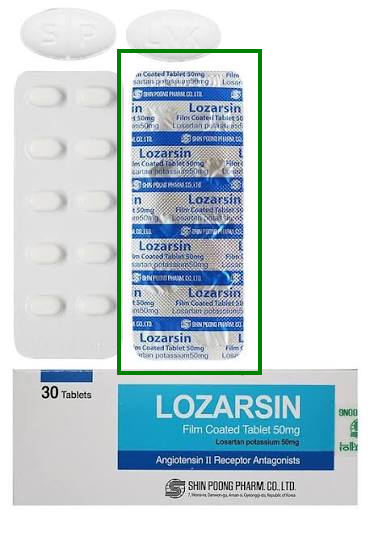

Detected regions: 1


In [25]:
from PIL import ImageDraw
from IPython.display import display

detected_image = image.copy()
draw = ImageDraw.Draw(detected_image)

regions = []

for prediction in predictions:
    if prediction.score < 0.25:
        continue

    x1, y1, x2, y2 = map(int, prediction.bboxes)
    regions.append((x1, y1, x2, y2))

    draw.rectangle(
        [x1, y1, x2, y2],
        outline="green",
        width=4
    )

display(detected_image)

print("Detected regions:", len(regions))

In [26]:
all_text = []

if not regions:
    regions = [(0, 0, image.width, image.height)]

for x1, y1, x2, y2 in regions:

    cropped = image.crop((x1, y1, x2, y2))

    results = reader.readtext(np.array(cropped))

    for box, text, confidence in results:
        all_text.append(text)
        print(f"{text} | Confidence: {confidence:.2f}")

full_text = " ".join(all_text)

print("\nExtracted Medicine Label Text:")
print(full_text)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


CC Lbreon | Confidence: 0.02
Lozarsin | Confidence: 0.99
erinuenui | Confidence: 0.00
Lozarsin | Confidence: 0.96
Lozan | Confidence: 0.61
Lozarsin | Confidence: 0.90
CNeanitnae | Confidence: 0.00
Lazarsir | Confidence: 0.60
4n | Confidence: 0.04
Lozarsin | Confidence: 1.00

Extracted Medicine Label Text:
CC Lbreon Lozarsin erinuenui Lozarsin Lozan Lozarsin CNeanitnae Lazarsir 4n Lozarsin


In [27]:
def extract_information(text):

    information = {
        "medicine_name": None,
        "expiry_date": None,
        "manufacturing_date": None,
        "batch_number": None,
        "strength": None
    }

    name = re.search(
        r"\b(ANAREX|ATENELOL|LOZARSIN|CALCIUM|PARACETAMOL)\b",
        text,
        re.IGNORECASE
    )

    if name:
        information["medicine_name"] = name.group(1).upper()

    expiry = re.search(
        r"(?:EXP|EXPIRY|EXPIRES)[\s:.-]*([A-Z0-9/-]+)",
        text,
        re.IGNORECASE
    )

    if expiry:
        information["expiry_date"] = expiry.group(1)

    manufacturing = re.search(
        r"(?:MFG|MFD)[\s:.-]*([A-Z0-9/-]+)",
        text,
        re.IGNORECASE
    )

    if manufacturing:
        information["manufacturing_date"] = manufacturing.group(1)

    batch = re.search(
        r"(?:BATCH|B\.?NO|LOT)[\s:.-]*([A-Z0-9-]+)",
        text,
        re.IGNORECASE
    )

    if batch:
        information["batch_number"] = batch.group(1)

    strengths = re.findall(
        r"\d+(?:\.\d+)?\s*(?:mg|mcg|ml|g|IU)",
        text,
        re.IGNORECASE
    )

    if strengths:
        information["strength"] = ", ".join(strengths)

    return information


medicine_info = extract_information(full_text)

for key, value in medicine_info.items():
    print(f"{key}: {value or 'Not detected'}")

medicine_name: LOZARSIN
expiry_date: Not detected
manufacturing_date: Not detected
batch_number: Not detected
strength: Not detected


In [28]:
def check_expiry(expiry_text):

    if not expiry_text:
        return "Expiry date could not be identified."

    months = {
        "JAN": 1, "FEB": 2, "MAR": 3,
        "APR": 4, "MAY": 5, "JUN": 6,
        "JUL": 7, "AUG": 8, "SEP": 9,
        "OCT": 10, "NOV": 11, "DEC": 12
    }

    match = re.search(
        r"([A-Z]{3})[A-Z]*\s*(\d{2,4})",
        expiry_text.upper()
    )

    if match:
        month = months.get(match.group(1))
        year = int(match.group(2))

    else:
        match = re.search(
            r"(\d{1,2})[/-](\d{2,4})",
            expiry_text
        )

        if not match:
            return "Expiry date format not recognized."

        month = int(match.group(1))
        year = int(match.group(2))

    if year < 100:
        year += 2000

    if not month or not 1 <= month <= 12:
        return "Invalid expiry date."

    today = date.today()

    if (year, month) < (today.year, today.month):
        return "EXPIRED"

    return "NOT EXPIRED (verify exact expiry date on packaging)"


expiry_status = check_expiry(medicine_info["expiry_date"])

print("Medicine Expiry Status:", expiry_status)

Medicine Expiry Status: Expiry date could not be identified.


In [31]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

image_path = next(iter(uploaded))
image = Image.open(image_path).convert("RGB")

predictions = predictor.predict(image)

print("Detection Results:")
print(predictions)

Saving image2.jpg to image2 (2).jpg
Detection Results:
[ObjectDetectionPrediction(score=0.8811823725700378, label_name='Calcium', label_index=1, id='5b591298-652d-4ef5-afb7-8b50a6a9ce1a', bboxes=(254, 88, 487, 404))]


Predicted medicine: Calcium
Confidence: 88.12%
Bounding box: (254, 88, 487, 404)


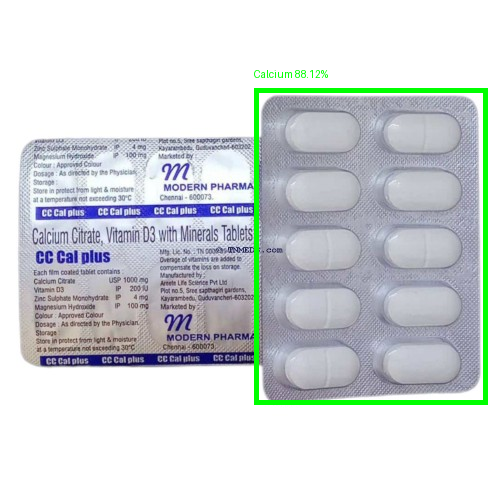

In [32]:
from PIL import ImageDraw
from IPython.display import display

detected_image = image.copy()
draw = ImageDraw.Draw(detected_image)

for prediction in predictions:
    x1, y1, x2, y2 = map(int, prediction.bboxes)
    label = prediction.label_name
    confidence = prediction.score * 100

    draw.rectangle([x1, y1, x2, y2], outline="lime", width=5)
    draw.text((x1, max(0, y1 - 20)), f"{label} {confidence:.2f}%", fill="lime")

    print("Predicted medicine:", label)
    print("Confidence:", f"{confidence:.2f}%")
    print("Bounding box:", (x1, y1, x2, y2))

display(detected_image)